# SC4000 — Learning to rank compiler configurations
## Frozen final system and experimental evidence

**Final public Kaggle score: 0.567 (user-reported). Frozen on 21 October 2026.**

We rank compiler configurations using collection-specific histogram gradient boosting
models and sampled graph neural networks, combining their predictions through rank
ensembles. A within-graph percentile target provides a useful complementary HGB model.

This is the consolidated final notebook. The exploratory notebooks contain the search
history; this notebook explains the final method and recreates its evidence in one place.
Its default run **does not train, tune, download the dataset, or perform fresh model
inference**. It loads an embedded, hash-checked evidence pack, generates report figures,
and exports the exact previously evaluated submission. The full checkpoint remains the
saved-model archive; its selected model files can be verified optionally below.

**Outputs:** `submission_final.csv`, ten PNG/PDF figures, supporting CSV tables,
figure captions, and a report artifact ZIP. The submission hash must be
`dc037f378ddb9d0892c283a26a7f31170ac6cc01e937e4d14f2847296ff80312`.

No other notebook or uploaded ZIP is needed for the default evidence replay.
Keep the complete model checkpoint separately: the compact embedded pack is not a model backup.


## 1. Run settings and frozen evidence

Run from top to bottom on Colab CPU or locally with NumPy, pandas and Matplotlib.
No package upgrades are performed. Those plotting packages are separate from the exact
scientific versions recorded for the trained model archive.

`MODEL_ARCHIVE` is optional: leave it empty to skip checking the full saved-model archive.
Set it to your complete downloaded ZIP or extracted results folder to verify all selected
models without loading pickle files. `DOWNLOAD_OUTPUTS` controls only the final browser
request; verify that the file actually reaches your computer.


In [1]:
from pathlib import Path
import os, sys, json, base64, hashlib, io, zipfile, types
BASE_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
OUTPUT_DIR = BASE_DIR / "sc4000_final_frozen"
MODEL_ARCHIVE = ""  # optional complete saved-model ZIP or extracted results folder
DOWNLOAD_OUTPUTS = False
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(OUTPUT_DIR / ".matplotlib")
from IPython.display import display, Image, Markdown


In [2]:
# Self-contained audited report code and compact frozen evidence; no training calls.
REPORT_SOURCE = '"""Read-only frozen evidence replay: charts, tables, archive verification and exact CSV export."""\nimport csv\nimport hashlib\nimport io\nimport json\nfrom pathlib import Path, PurePosixPath\nimport zipfile\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\n\nSHORT={\'layout:nlp:default\':\'NLP default\',\'layout:nlp:random\':\'NLP random\',\n       \'layout:xla:default\':\'XLA default\',\'layout:xla:random\':\'XLA random\',\'tile:xla\':\'Tile XLA\'}\nCOLORS=[\'#286f8e\',\'#d27b32\',\'#3a8c6c\',\'#835a9b\',\'#65737e\',\'#a44848\']\n\n\ndef sha(data):return hashlib.sha256(data).hexdigest()\ndef read(path):return json.loads(Path(path).read_text())\n\n\ndef unpack(payload,expected_sha,dest):\n    if sha(payload)!=expected_sha:raise ValueError(\'Frozen evidence package hash mismatch\')\n    dest=Path(dest);dest.mkdir(parents=True,exist_ok=True)\n    with zipfile.ZipFile(io.BytesIO(payload)) as z:\n        if sum(i.file_size for i in z.infolist())>20*1024**2:\n            raise ValueError(\'Unexpected evidence package size\')\n        manifest=json.loads(z.read(\'freeze_manifest.json\'))\n        if set(z.namelist())!=set(manifest[\'files\'])|{\'freeze_manifest.json\'}:\n            raise ValueError(\'Unexpected package contents\')\n        for name in z.namelist():\n            rel=PurePosixPath(name)\n            if rel.is_absolute() or \'..\' in rel.parts:raise ValueError(\'Invalid package path\')\n            data=z.read(name)\n            if name!=\'freeze_manifest.json\' and sha(data)!=manifest[\'files\'][name][\'sha256\']:\n                raise ValueError(\'Artifact hash mismatch: \'+name)\n            path=dest/name\n            if path.exists() and path.read_bytes()!=data:\n                raise ValueError(\'Existing evidence differs; choose a new OUTPUT_DIR: \'+str(path))\n            path.parent.mkdir(parents=True,exist_ok=True);path.write_bytes(data)\n    return manifest\n\n\ndef validate_submission(evidence):\n    evidence=Path(evidence);data=(evidence/\'submission_selected.csv\').read_bytes()\n    manifest=read(evidence/\'freeze_manifest.json\')\n    if sha(data)!=manifest[\'submission_sha256\']:raise ValueError(\'Frozen submission changed\')\n    rows=list(csv.DictReader(io.StringIO(data.decode())))\n    constraints=list(csv.DictReader(io.StringIO((evidence/\'tables/submission_constraints.csv\').read_text())))\n    if len(rows)!=manifest[\'submission_rows\'] or len(rows)!=len(constraints):raise ValueError(\'Row count mismatch\')\n    if len({r[\'ID\'] for r in rows})!=len(rows):raise ValueError(\'Duplicate IDs\')\n    for r,t in zip(rows,constraints):\n        ids=list(map(int,r[\'TopConfigs\'].split(\';\')));n=int(t[\'candidate_count\']);k=int(t[\'length\'])\n        if r[\'ID\']!=t[\'ID\'] or len(ids)!=k or len(set(ids))!=k:raise ValueError(\'Ranking identity/length mismatch\')\n        if any(v<0 or v>=n for v in ids[:min(k,n)]):raise ValueError(\'Candidate out of bounds\')\n        if t[\'collection\'].startswith(\'layout\'):\n            if k>n or (k==n and sorted(ids)!=list(range(n))):raise ValueError(\'Invalid layout ranking\')\n        elif k>n and ids[n:]!=list(range(n,k)):raise ValueError(\'Invalid short-tile padding\')\n        if sha(r[\'TopConfigs\'].encode())!=t[\'ranking_sha256\']:raise ValueError(\'Ranking changed\')\n    return dict(rows=len(rows),sha256=sha(data),collections=len({r[\'collection\'] for r in constraints}))\n\n\ndef verify_model_archive(path,evidence):\n    """Optional streaming hash check; does not unpickle or execute archived code."""\n    path=Path(path);models=pd.read_csv(Path(evidence)/\'tables/model_inventory.csv\')\n    def checksum(stream):\n        h=hashlib.sha256()\n        for chunk in iter(lambda:stream.read(1024**2),b\'\'):h.update(chunk)\n        return h.hexdigest()\n    if path.is_dir():\n        for row in models.itertuples():\n            with (path/row.path).open(\'rb\') as f:actual=checksum(f)\n            if actual!=row.sha256:raise ValueError(\'Model differs: \'+row.path)\n    else:\n        with zipfile.ZipFile(path) as z:\n            for row in models.itertuples():\n                with z.open(row.path) as f:actual=checksum(f)\n                if actual!=row.sha256:raise ValueError(\'Model differs: \'+row.path)\n    return f\'Verified {len(models)} selected model files; no models loaded or fitted.\'\n\n\ndef export_submission(evidence,output):\n    validation=validate_submission(evidence)\n    path=Path(output)/\'submission_final.csv\';data=(Path(evidence)/\'submission_selected.csv\').read_bytes()\n    if path.exists() and path.read_bytes()!=data:raise ValueError(\'Refusing to replace a different submission\')\n    path.write_bytes(data)\n    (Path(output)/\'submission_verification.json\').write_text(json.dumps(validation,indent=2)+\'\\n\')\n    return path\n\n\ndef generate(evidence,output):\n    evidence=Path(evidence);output=Path(output);figdir=output/\'figures\';tabdir=output/\'tables\'\n    figdir.mkdir(parents=True,exist_ok=True);tabdir.mkdir(exist_ok=True)\n    load=lambda n:pd.read_csv(evidence/\'tables\'/f\'{n}.csv\')\n    captions=[]\n    plt.rcParams.update({\'font.size\':10,\'axes.spines.top\':False,\'axes.spines.right\':False,\n        \'figure.dpi\':110,\'savefig.dpi\':180,\'pdf.fonttype\':42})\n    def save(fig,name,caption):\n        fig.tight_layout()\n        for ext in [\'png\',\'pdf\']:fig.savefig(figdir/f\'{name}.{ext}\',bbox_inches=\'tight\')\n        plt.close(fig);captions.append(f\'**{name}.** {caption}\')\n    def table(frame,name):frame.to_csv(tabdir/f\'{name}.csv\',index=False)\n\n    recipes=read(evidence/\'selected_recipes.json\')\n    description=[]\n    for r in recipes:\n        e=r[\'experiment\']\n        description.append(dict(collection=SHORT[r[\'collection\']],model=r[\'name\'],weight=r[\'weight\'],\n            family=e[\'model\'],target=e.get(\'target\',e.get(\'loss\')),node_budget=e.get(\'profile\',{}).get(\'nodes\'),\n            configs_per_graph=e.get(\'configs\'),training_graph_cap=e.get(\'train_graphs\')))\n    table(pd.DataFrame(description),\'final_model_recipe\')\n    table(load(\'selected_training_sizes\'),\'actual_training_sizes\')\n    table(load(\'selected_audit_summary\'),\'target_blend_audit\')\n    table(load(\'component_ablation_sources\'),\'component_ablations\')\n\n    fig,ax=plt.subplots(figsize=(11,4));ax.set_xlim(0,11);ax.set_ylim(0,4);ax.axis(\'off\')\n    nodes=[(1,2,\'NPZ graphs +\\nconfigurations\'),(3.4,2,\'Graph-disjoint\\ndevelopment folds\'),\n        (6,3,\'Masked / categorical\\ntabular features → HGB\'),(6,1,\'Bounded graph + layout\\npairwise GNN (XLA)\'),\n        (9,2,\'Frozen rank blend\\nper collection\'),(9,.2,\'894-row submission\')]\n    for x,y,text in nodes:ax.text(x,y,text,ha=\'center\',va=\'center\',fontsize=10,\n        bbox=dict(boxstyle=\'round,pad=.55\',facecolor=\'#edf4f6\',edgecolor=\'#467187\'))\n    for a,b in [((1.9,2),(2.3,2)),((4.5,2.2),(4.7,2.9)),((4.5,1.8),(4.7,1.1)),\n                ((7.3,3),(8,2.3)),((7.3,1),(8,1.7)),((9,1.5),(9,.6))]:\n        ax.annotate(\'\',xy=b,xytext=a,arrowprops=dict(arrowstyle=\'->\',color=\'#476071\'))\n    save(fig,\'01_pipeline\',\'Training workflow that produced the frozen system. This notebook replays its evidence; it does not rerun this training pipeline.\')\n\n    inv=load(\'dataset_inventory\');cov=load(\'coverage_sources\')\n    fig,axes=plt.subplots(1,2,figsize=(11,4))\n    cs=list(SHORT);axes[0].boxplot([inv[inv.collection==c].nodes for c in cs],showfliers=False)\n    axes[0].set_xticks(range(1,6),[SHORT[c] for c in cs],rotation=25,ha=\'right\')\n    axes[0].set_yscale(\'log\');axes[0].set_ylabel(\'Nodes per supplied training graph (log)\')\n    for i,c in enumerate([\'layout:xla:default\',\'layout:xla:random\']):\n        g=cov[(cov.collection==c)&(cov.sampler==\'uniform\')].groupby(\'nodes_budget\')[[\'node_fraction\',\'edge_fraction\']].median()\n        for col,style in [(\'node_fraction\',\'-\'),(\'edge_fraction\',\'--\')]:\n            axes[1].plot(g.index,100*g[col],style,marker=\'o\',color=COLORS[i],label=SHORT[c]+\' \'+col.split(\'_\')[0])\n    axes[1].set_xlabel(\'Node budget\');axes[1].set_ylabel(\'Median retained fraction (%)\');axes[1].legend(fontsize=8)\n    save(fig,\'02_data_and_coverage\',\'Left: supplied training graph inventory; boxplot outliers hidden. Right: uniform-sampled audit graph coverage; edge denominator is the pre-capped context, not necessarily the original complete graph. Node/configurable-node/edge caps co-vary.\')\n    table(inv.groupby(\'collection\').agg(graphs=(\'graph\',\'count\'),median_nodes=(\'nodes\',\'median\'),max_nodes=(\'nodes\',\'max\')).reset_index(),\'dataset_summary\')\n\n    f=load(\'component_ablation_sources\');fig,axes=plt.subplots(1,2,figsize=(11,3.8))\n    for ax,c in zip(axes,[\'layout:xla:default\',\'layout:xla:random\']):\n        g=f[f.collection==c].reset_index(drop=True)\n        for i,r in g.iterrows():ax.plot([r.bootstrap_low,r.bootstrap_high],[i,i],color=COLORS[0]);ax.plot(r.mean_paired_gain,i,\'o\',color=COLORS[0])\n        ax.axvline(0,color=\'grey\',ls=\'--\');ax.set_yticks(range(len(g)),g.factor)\n        ax.set_title(SHORT[c]);ax.set_xlabel(\'Paired development tau change\')\n    save(fig,\'03_component_ablations\',\'Confirmed component comparisons against their specified controls. Exploratory graph-bootstrap intervals, not multiplicity-corrected. All intervals shown cross zero; do not claim independently established gains for masks or context. Not a cumulative waterfall.\')\n\n    f=load(\'coverage_score_sources\');fig,axes=plt.subplots(1,2,figsize=(10,3.6))\n    for ax,c in zip(axes,[\'layout:xla:default\',\'layout:xla:random\']):\n        for label,color in [(\'reference\',COLORS[0]),(\'full\',COLORS[1])]:\n            g=f[(f.collection==c)&f.experiment.str.startswith(\'G_\'+label+\'_\')].copy()\n            g[\'nodes\']=g.experiment.str.extract(r\'n(\\d+)$\')[0].astype(int)\n            a=g.groupby(\'nodes\').score.mean();ax.plot(a.index,a,\'o-\',color=color,label=label)\n        ax.set_title(SHORT[c]);ax.set_xlabel(\'Node budget\');ax.set_ylabel(\'Development tau\');ax.legend()\n    save(fig,\'04_graph_budget\',\'Seed-42 screening averaged over two development folds. Larger sampled graphs did not consistently improve scores. Other graph caps co-vary; missing settings are not zero.\')\n\n    f=load(\'training_grid_sources\');fig,axes=plt.subplots(1,2,figsize=(10,3.8))\n    for ax,c in zip(axes,[\'layout:xla:default\',\'layout:xla:random\']):\n        g=f[f.collection==c].pivot(index=\'graphs\',columns=\'configs\',values=\'score\').reindex(index=[24,40,0],columns=[64,128,256])\n        im=ax.imshow(np.ma.masked_invalid(g.to_numpy()),cmap=\'viridis\')\n        fig.colorbar(im,ax=ax,label=\'Development tau\')\n        for i in range(3):\n            for j in range(3):\n                v=g.iloc[i,j];color=\'black\' if pd.notna(v) and im.norm(v)>.65 else \'white\'\n                ax.text(j,i,f\'{v:.3f}\' if pd.notna(v) else \'not run\',ha=\'center\',va=\'center\',color=color)\n        ax.set_xticks(range(3),[64,128,256]);ax.set_yticks(range(3),[\'24\',\'40\',\'all eligible\'])\n        ax.set_xlabel(\'Configurations per training graph\');ax.set_ylabel(\'Training graphs\');ax.set_title(SHORT[c])\n    save(fig,\'05_training_data\',\'Seed-42 data-budget screening, two-fold mean at the selected graph budget. “All eligible” excludes each fold’s development graphs. More examples also increase optimiser steps, so this is not compute-matched.\')\n\n    f=load(\'trial_results\');f=f[f.seed==42].copy();f[\'collection\']=f.collection.str.replace(\'_\',\':\',n=2)\n    names=[\'HGB_control\',\'V5_H_percentile\',\'V5_X_regression\',\'V5_X_pairwise\']\n    labels=[\'HGB\\ncontrol\',\'HGB\\npercentile\',\'XGB\\nregression\',\'XGB\\npairwise\']\n    fig,axes=plt.subplots(2,2,figsize=(10,7))\n    for ax,c in zip(axes.flat,list(SHORT)[:4]):\n        g=f[f.collection==c].pivot(index=\'experiment\',columns=\'fold\',values=\'dev_score\').reindex(names)\n        for i,fold in enumerate([0,1]):ax.bar(np.arange(4)+(i-.5)*.35,g[fold],.35,label=f\'Fold {fold}\',color=COLORS[i])\n        ax.set_xticks(range(4),labels);ax.set_title(SHORT[c]);ax.set_ylabel(\'Development tau\');ax.legend(fontsize=8)\n    save(fig,\'06_target_and_objective\',\'Matched example IDs per fold/seed. HGB control versus percentile isolates target transformation; XGB regression versus pairwise isolates objective within its fixed learner settings. HGB versus XGB changes learner/capacity. Seed-42 screening only; no XGB model was selected.\')\n\n    base=load(\'final_system_sources\');audit=load(\'selected_audit_summary\');rows=[]\n    for c in SHORT:\n        basic=float(base[(base.collection==c)&(base.system==\'baseline\')].score.iloc[0])\n        if c.startswith(\'layout\'):\n            selected=float(audit[audit.collection==c].candidate_score.iloc[0]);n=int(audit[audit.collection==c].graphs.iloc[0])\n        else:\n            r=base[(base.collection==c)&(base.system==\'selected\')].iloc[0];selected=float(r.score);n=int(r.graphs)\n        rows.append(dict(collection=c,baseline=basic,final_selected=selected,audit_graphs=n))\n    comparison=pd.DataFrame(rows);table(comparison,\'baseline_and_final_audit\')\n    fig,axes=plt.subplots(1,2,figsize=(11,4),gridspec_kw={\'width_ratios\':[3,1]})\n    for ax,collections in zip(axes,[list(SHORT)[:4],[\'tile:xla\']]):\n        g=comparison.set_index(\'collection\').loc[collections];x=np.arange(len(g))\n        ax.bar(x-.18,g.baseline,.36,color=COLORS[0],label=\'Basic HGB baseline\')\n        ax.bar(x+.18,g.final_selected,.36,color=COLORS[2],label=\'Frozen final system\')\n        ax.set_xticks(x,[SHORT[c] for c in collections],rotation=20,ha=\'right\');ax.legend(fontsize=8)\n    axes[0].set_ylabel(\'Mean sampled audit Kendall tau\');axes[1].set_ylabel(\'Mean sampled 1 − top-5 regret\')\n    save(fig,\'07_final_audit\',\'Previously inspected official-validation audit: 20 graphs per NLP collection, 7 per XLA layout, 24 Tile. Baseline and selected are saved ensembles. Metrics differ between panels; do not average them into a Kaggle estimate. Reuse makes this exploratory evidence, not a new untouched test.\')\n\n    f=pd.DataFrame(read(evidence/\'reported_kaggle_scores.json\'));table(f,\'reported_public_scores\')\n    fig,ax=plt.subplots(figsize=(9,3.8));bars=ax.bar(range(len(f)),f.score,color=[COLORS[4]]*4+[COLORS[2]])\n    ax.set_xticks(range(len(f)),[\'Basic\\nbaseline\',\'Tabular\\nsystem\',\'Initial\\nhybrid\',\'Data/training\\nextension\',\'Final selected\\nsystem\'])\n    for b,r in zip(bars,f.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.008,(\'≈\' if r.precision==\'approximate\' else \'\')+f\'{r.score:.3f}\',ha=\'center\')\n    ax.set_ylim(0,.64);ax.set_ylabel(\'Public Kaggle score (user-reported)\')\n    save(fig,\'08_public_scores\',\'User-reported public scores; first three are approximate. Final 0.567 versus 0.558: +0.009 absolute (+1.61% relative). Verify exact scores and current rank with a screenshot before report submission. No inferred leaderboard percentile.\')\n\n    f=load(\'selected_gnn_histories\');fig,axes=plt.subplots(2,2,figsize=(11,7))\n    diagnostics=[]\n    for row,c in enumerate([\'layout:xla:default\',\'layout:xla:random\']):\n        for i,((fold,seed),g) in enumerate(f[f.collection==c].groupby([\'fold\',\'seed\'])):\n            g=g.sort_values(\'epoch\');best=int(g.selected_epoch.iloc[0]);selected=g[g.epoch==best].iloc[0]\n            label=f\'Fold {fold}, seed {seed}\'\n            for ax,col in zip(axes[row],[\'loss\',\'early_dev_score\']):\n                ax.plot(g.epoch,g[col],color=COLORS[i],label=label,alpha=.85,linewidth=1.4)\n                ax.plot(best,selected[col],\'o\',color=COLORS[i],markersize=4)\n            diagnostics.append(dict(collection=c,fold=fold,seed=seed,selected_epoch=best,\n                epochs_run=int(g.epoch.max()),first_loss=g.loss.iloc[0],last_loss=g.loss.iloc[-1],\n                selected_dev_tau=selected.early_dev_score,last_dev_tau=g.early_dev_score.iloc[-1]))\n        axes[row,0].set_ylabel(\'Mean training batch loss\');axes[row,1].set_ylabel(\'Early-development Kendall tau\')\n        for ax in axes[row]:ax.set_title(SHORT[c]);ax.set_xlabel(\'Epoch\');ax.legend(fontsize=7,ncol=2)\n    table(pd.DataFrame(diagnostics),\'gnn_learning_diagnostics\')\n    save(fig,\'09_gnn_learning_curves\',\'Actual selected GNN histories; dots mark saved selected epochs. Left: mean training batch loss (pairwise objective with regression fallback on batches lacking eligible pairs). Right: ranking score on the smaller early-stopping development subset, not validation loss or the full selection metric. Individual fold/seed curves are unsmoothed; no claim of absence of overfitting.\')\n\n    f=load(\'worker_resources\');f=f[f.label.str.endswith(\'| trial\')]\n    fig,axes=plt.subplots(1,2,figsize=(10,3.5))\n    axes[0].plot(range(1,len(f)+1),f.wall_seconds/60,\'o\',color=COLORS[0]);axes[0].set_ylabel(\'Worker wall time (minutes)\')\n    axes[1].plot(range(1,len(f)+1),f.peak_rss_gib,\'o\',color=COLORS[2]);axes[1].set_ylabel(\'Worker peak RSS (GiB)\')\n    for ax in axes:ax.set_xlabel(\'Completed target/objective training job\')\n    save(fig,\'10_training_resources\',\'Measured workers in the target/objective study. Parallel job times are not total elapsed time; extraction, inference and backups are additional. Worker RSS excludes the rest of the Colab session.\')\n    (output/\'FIGURE_CAPTIONS.md\').write_text(\'# Figure captions\\n\\n\'+\'\\n\\n\'.join(captions)+\'\\n\')\n    return figdir\n'
EVIDENCE_B64 = '...'
EVIDENCE_SHA256 = 'c6283a5700c1fa8aecac1fe808637ee9444d0e388588bfb270ca79deda315c80'
final_report = types.ModuleType("sc4000_final_report")
exec(compile(REPORT_SOURCE, "embedded_final_report.py", "exec"), final_report.__dict__)
EVIDENCE_DIR = OUTPUT_DIR / "evidence"
freeze = final_report.unpack(base64.b64decode(EVIDENCE_B64), EVIDENCE_SHA256, EVIDENCE_DIR)
print("Frozen submission:", freeze["submission_sha256"])
print("Rows:", freeze["submission_rows"], "| selected model files:", freeze["selected_model_files"])
print("Public score:", freeze["public_score_user_reported"], "(user-reported)")


Frozen submission: dc037f378ddb9d0892c283a26a7f31170ac6cc01e937e4d14f2847296ff80312
Rows: 894 | selected model files: 60
Public score: 0.567 (user-reported)


In [3]:
import pandas as pd
import numpy as np
FIGURES = final_report.generate(EVIDENCE_DIR, OUTPUT_DIR)
def table(name):
    return pd.read_csv(OUTPUT_DIR / "tables" / (name + ".csv"))
def evidence_table(name):
    return pd.read_csv(EVIDENCE_DIR / "tables" / (name + ".csv"))
def show_figure(name):
    display(Image(filename=str(FIGURES / (name + ".png"))))
print("Report figures and source tables regenerated from saved evidence.")


Report figures and source tables regenerated from saved evidence.


## 2. Task, data and evaluation

The input is a computation graph and candidate compiler configurations. The output is
an ordering of configuration IDs, with faster predicted candidates first. There are five
collections: NLP default/random layout, XLA default/random layout, and XLA tiling. These
are dataset groups, not model families. Each has its own selected predictor or blend.

The saved training inventory below describes all supplied training graphs. Actual model
fits use bounded subsets, documented later. Layout graphs can be large, and the number
of configurations makes fully materializing their arrays expensive.

For local **layout** evaluation we use Kendall's tau between runtimes and predicted
costs: higher is better. For **Tile** we use one minus top-five regret on sampled
candidates, where regret is `fastest_runtime_among_predicted_top5 / best_runtime - 1`.
Local candidate subsets and graph counts differ from full Kaggle evaluation; the metrics
must not be averaged or treated as interchangeable with the public score.

The final CSV follows each sample-submission row's required output length. A layout row
need not contain every possible candidate when the template requests fewer. Short Tile
rows retain the established template-padding convention.


,collection,graphs,median_nodes,max_nodes
0,layout:nlp:default,198,3296.0,21919
1,layout:nlp:random,207,3296.0,21919
2,layout:xla:default,61,10092.0,43615
3,layout:xla:random,69,10449.0,43615
4,tile:xla,5709,35.0,394


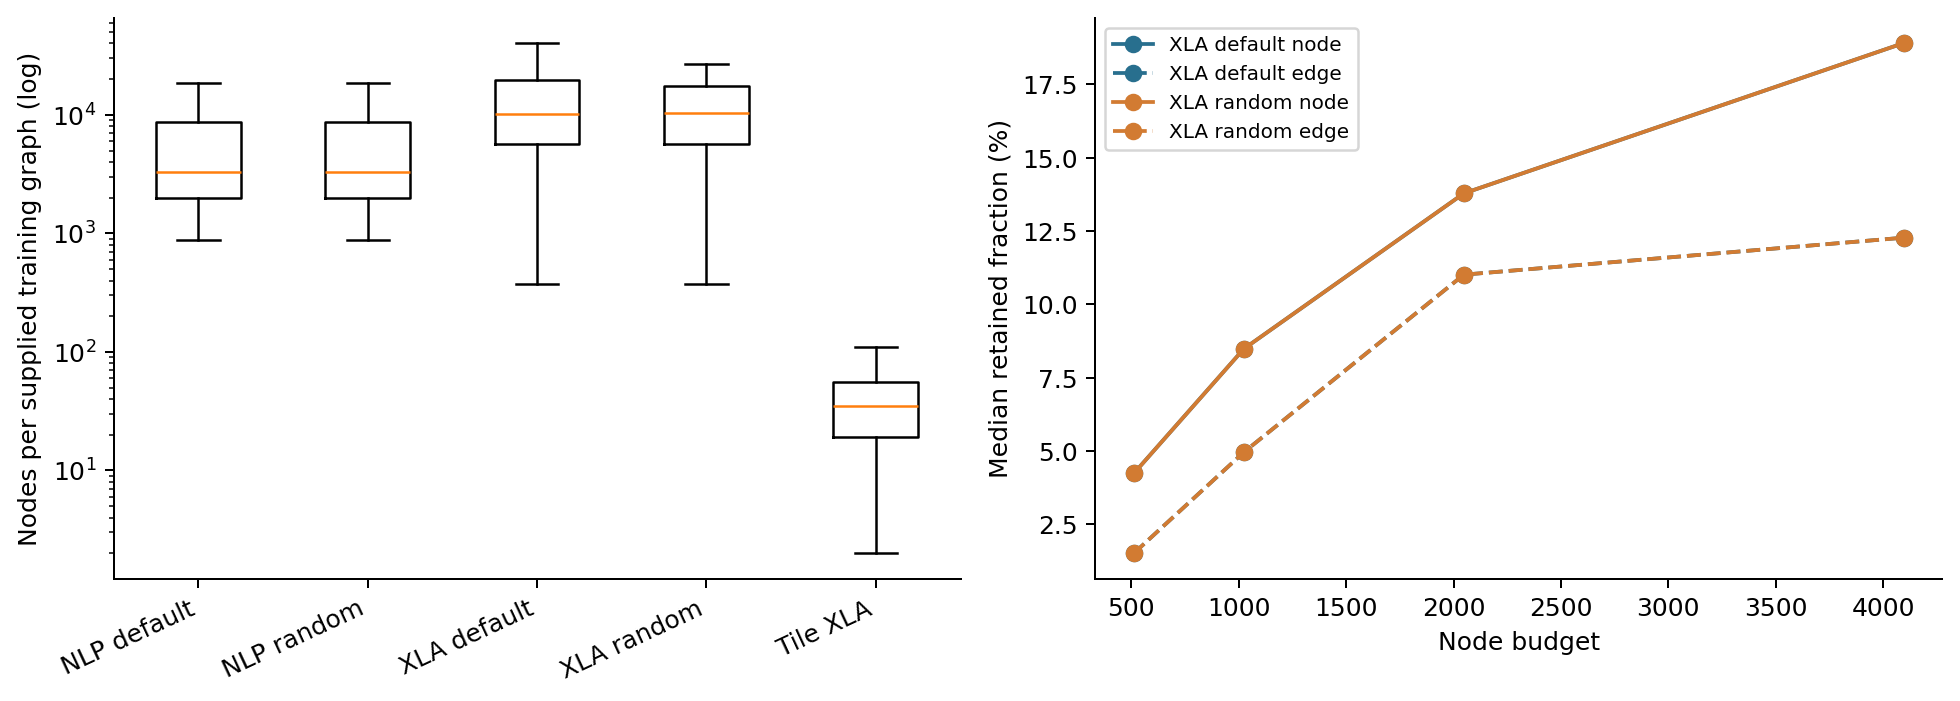

In [4]:
display(table("dataset_summary"))
show_figure("02_data_and_coverage")


## 3. Preprocessing and representation

**Graph-level splitting.** Two fixed development folds reserve disjoint development graph
blocks. Within each fold, its development graphs are excluded from training. A graph may
be used for training in the other fold; that other model is not used to score its development
fold. Official validation graphs form an audit set that has already been inspected during
exploration. We do not describe it as a new untouched test set.

**Configuration sampling and memory bounds.** Fixed label-independent candidate pools
and recorded training-ID manifests make comparisons repeatable. Selected configuration
rows are streamed from NPZ members in bounded chunks; full layout tensors are not loaded
at once. Graph/configuration caps, matrix guards, isolated workers and scratch cleanup
keep the training workflow within the intended 12–13 GB Colab CPU environment. Limits
can exclude an experiment; exclusion does not mean that model performed badly.

**Layout features.** The `-1` sentinel is distinguished from valid axis categories. We
compute masked statistics and validity fractions, per-position categorical histograms,
hashed opcode/layout and depth/layout summaries, edge-category co-occurrences, and compact
graph topology features. Axis IDs in categorical histograms are categories, not physical
sizes. The HGB feature blocks used by each selected model are recorded in the recipe JSON.

**Tile features.** The 24 numeric configuration inputs use raw summaries, signed-log
transforms and selected pair interactions alongside graph summaries. Layout padding
semantics are not imposed on Tile inputs.

**Targets and weights.** Original HGB models predict `log(1 + runtime)` centered by the
training graph's median. The alternative target is `(rank(runtime) - 1)/(m - 1)` within
the selected training configurations of each graph (with denominator at least one).
Ties use average ranks. Graph weighting prevents configuration-rich graphs from dominating
simply through their row counts. Validation runtimes are never used to construct training
labels or label-independent features.


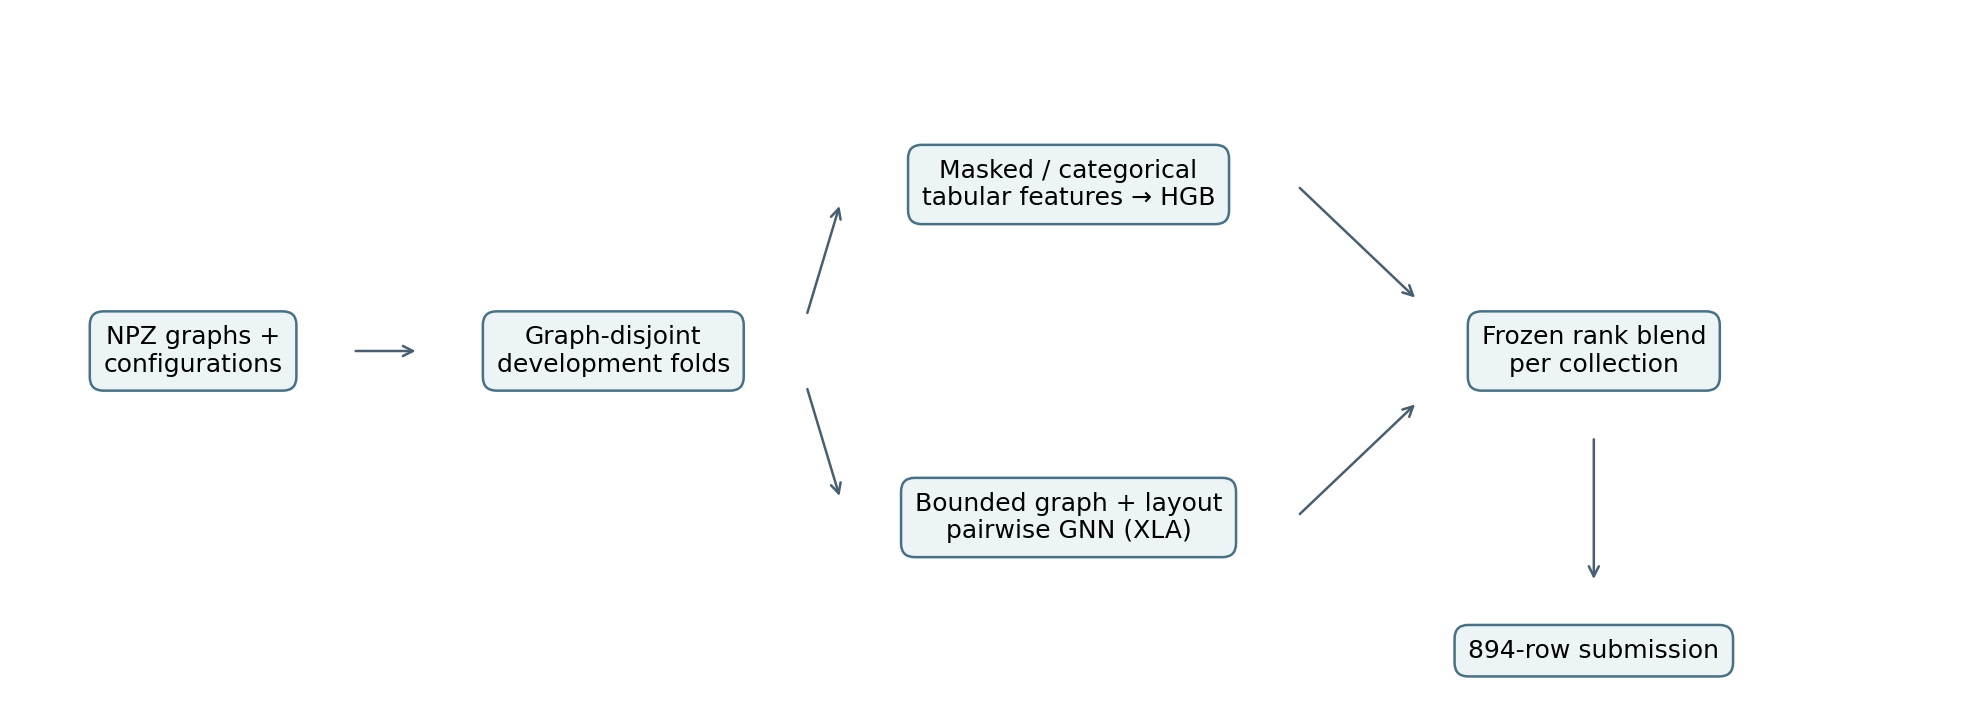

,collection,fold,split,graphs,candidate_pool_rows
1,layout:nlp:default,0,dev,12,12288
2,layout:nlp:default,0,holdout,20,20480
4,layout:nlp:default,1,dev,12,12288
5,layout:nlp:default,1,holdout,20,20480
7,layout:nlp:random,0,dev,12,12288
8,layout:nlp:random,0,holdout,20,20480
10,layout:nlp:random,1,dev,12,12288
11,layout:nlp:random,1,holdout,20,20480
13,layout:xla:default,0,dev,12,12288
14,layout:xla:default,0,holdout,7,7168


In [5]:
show_figure("01_pipeline")
display(evidence_table("reference_split_inventory").query("split != 'train'"))


## 4. Models and the frozen final recipe

**Baseline:** basic-summary histogram gradient boosting (`B0_basic_hgb`). A richer
feature HGB provides the stronger tabular comparison. Differences in training size and
capacity are documented; the complete pipeline comparison is not a single-component ablation.

**Sampled GNN:** a 16-dimensional opcode embedding, standardized numeric node features,
configuration values and optional validity masks feed a width-32 network with two directed
mean-neighbour message-passing layers and residual updates. Mean/max pooling over all
retained nodes and configurable nodes is combined with optional context summaries. A
pairwise hinge objective encourages lower predicted cost for faster configurations;
batches without eligible runtime differences fall back to smooth-L1 regression.

The selected XLA default GNN uses a 2,048-node cap and 256 training configurations per
graph; the selected XLA random GNN uses 512 nodes and 128 configurations. Both use all
eligible training graphs for their fold. These caps do not imply complete graph retention.

**Final ensemble:** each saved fold/seed predictor scores candidates; scores are converted
to within-graph normalized ranks before averaging and blending. The weights below are
fixed by development selection. They are not weights learned from Kaggle test labels.
No XGBoost model was retained in the final system.

The table keeps original experiment IDs so every entry can be traced to a saved model.
A training graph cap of zero means all eligible graphs, not zero examples. The actual
counts in the second table are the authoritative record of what each model saw.


In [6]:
display(table("final_model_recipe"))
sizes = table("actual_training_sizes")
display(sizes.groupby(["collection", "experiment", "fold"], as_index=False).agg(
    training_graphs=("graphs", "first"), configurations=("configurations", "first"),
    min_configs=("min_configs", "min"), max_configs=("max_configs", "max")))


,collection,model,weight,family,target,node_budget,configs_per_graph,training_graph_cap
0,NLP default,T_deeper_hgb,0.250,hgb,centered_log,NaN,256,128
1,NLP default,V5_H_percentile,0.750,hgb,percentile,NaN,256,128
2,NLP random,V4_T_gall_c384,0.500,hgb,centered_log,NaN,384,0
3,NLP random,V5_H_percentile,0.500,hgb,percentile,NaN,384,0
4,XLA default,T_full_small,0.375,hgb,centered_log,NaN,256,40
5,XLA default,G_data_gall_c256,0.375,gnn,pairwise,2048.0,256,0
6,XLA default,V5_H_percentile,0.250,hgb,percentile,NaN,256,40
7,XLA random,T_deeper_hgb,0.250,hgb,centered_log,NaN,256,128
8,XLA random,G_data_gall_c128,0.750,gnn,pairwise,512.0,128,0
9,Tile XLA,T_deeper_hgb,1.000,hgb,centered_log,NaN,256,320


,collection,experiment,fold,training_graphs,configurations,min_configs,max_configs
0,layout:nlp:default,T_deeper_hgb,0,128,32768,256,256
1,layout:nlp:default,T_deeper_hgb,1,128,32768,256,256
2,layout:nlp:default,V5_H_percentile,0,128,32768,256,256
3,layout:nlp:default,V5_H_percentile,1,128,32768,256,256
4,layout:nlp:random,V4_T_gall_c384,0,195,74880,384,384
5,layout:nlp:random,V4_T_gall_c384,1,195,74880,384,384
6,layout:nlp:random,V5_H_percentile,0,195,74880,384,384
7,layout:nlp:random,V5_H_percentile,1,195,74880,384,384
8,layout:xla:default,G_data_gall_c256,0,49,12544,256,256
9,layout:xla:default,G_data_gall_c256,1,49,12544,256,256


## 5. What the ablations establish

### Components and graph structure

We tested validity masks, context summaries, message passing, graph budgets and training
budgets. These are distinct comparisons, not cumulative improvements that can be added.
The component plot uses graph-paired comparisons and exploratory bootstrap intervals.
**All displayed mask/context/message-passing intervals cross zero.** Therefore this
experiment does not establish a clear standalone benefit for those components. A final
model can contain a component without its individual gain having been proven.

Increasing the sampled graph budget did not consistently improve development scores.
Changing training graph/configuration counts sometimes helped, but the effect varied by
collection and fold. More training examples also change the number of optimizer steps;
we do not claim a compute-matched scaling law. Coverage limits are a plausible constraint,
not a demonstrated cause of poorer GNN performance.


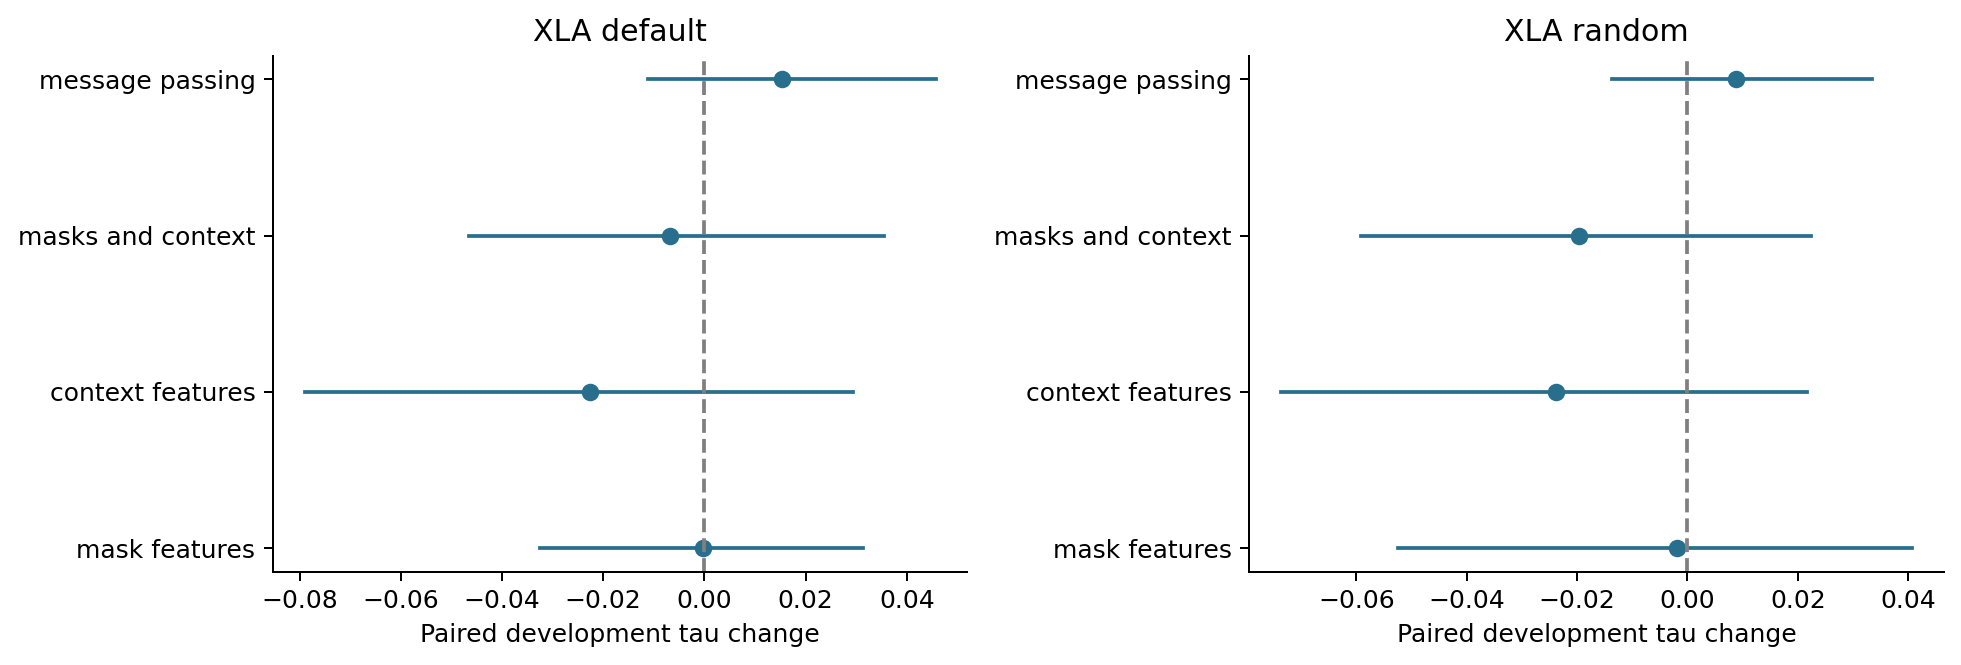

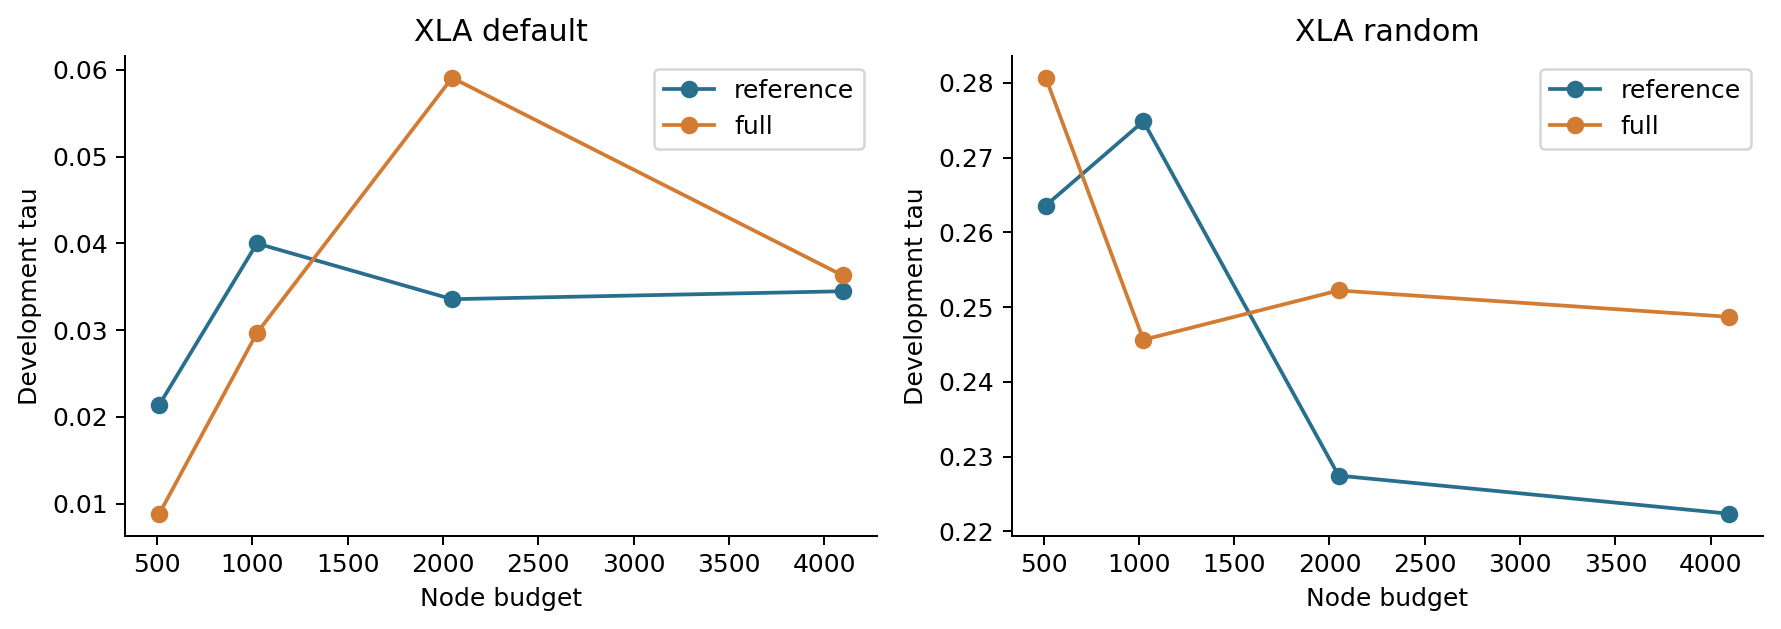

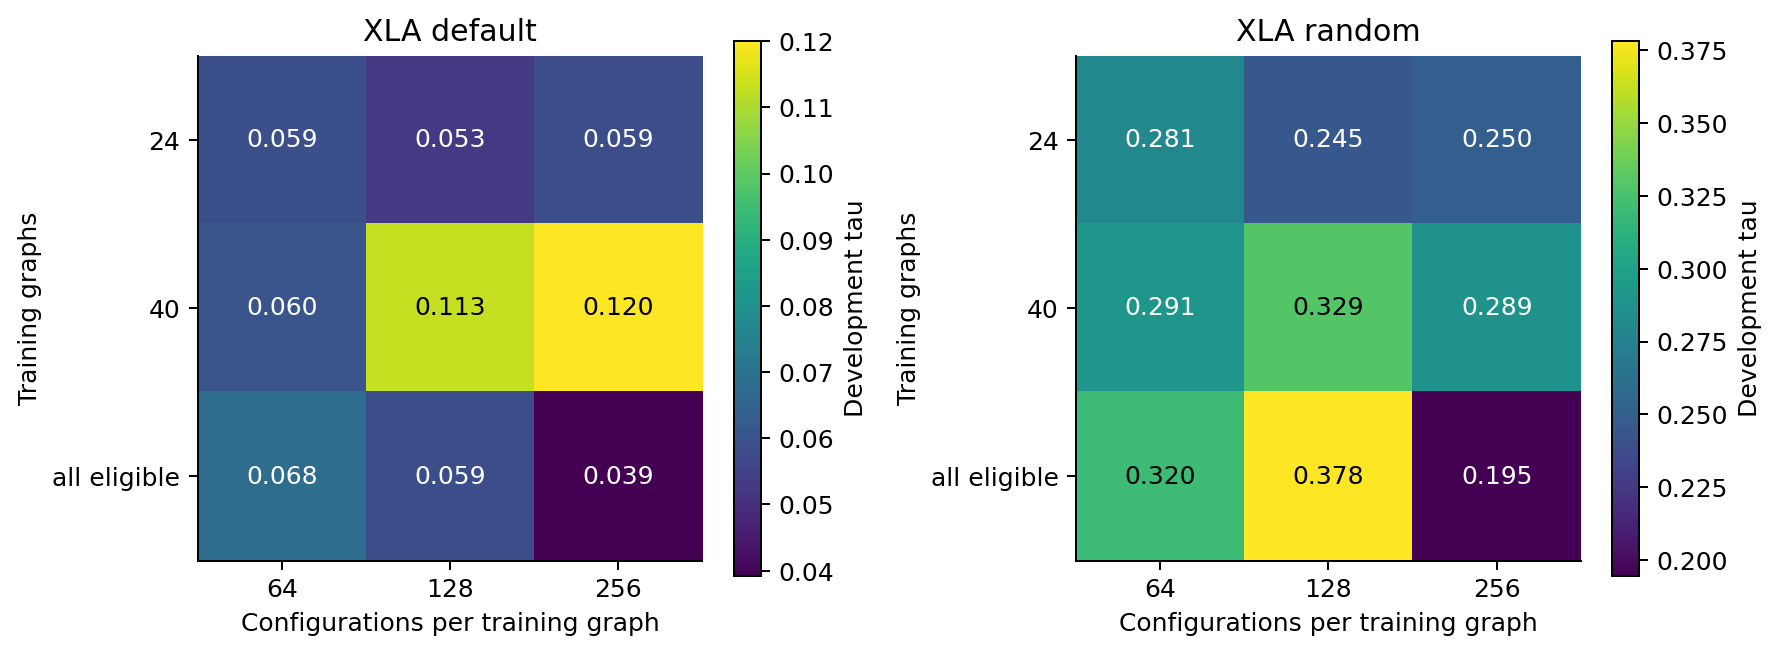

In [7]:
show_figure("03_component_ablations")
show_figure("04_graph_budget")
show_figure("05_training_data")


### Training-data expansion and target/objective comparisons

Expanding tabular training data helped NLP random in the earlier development selection;
the existing NLP default and Tile predictors were retained. Larger Tile settings met
resource exclusions, so they cannot be called negative performance results. Longer GNN
training did not pass the fold-consistency selection rule.

The final controlled study kept graph/configuration IDs matched to the selected tabular
reference and compared: (1) percentile-target HGB; (2) XGBoost regression; and (3) grouped
XGBoost pairwise ranking. HGB control versus percentile changes the target. XGBoost
regression versus pairwise changes the objective within fixed XGBoost settings. Comparing
HGB directly with XGBoost also changes learner/capacity.

Screening used seed 42 on two folds. Promising models received seeds 137 and 2026. A
small predefined blend grid was eligible only if its mean development gain was at least
0.002 and neither fold regressed. This is a practical selection rule, not a significance
test. Some deterministic tree predictions are identical across seeds; repeated seeds
are not independent graph replications.

**Result:** percentile HGB complements the incumbent on NLP default, NLP random and XLA
default. In NLP random, the percentile model alone is slightly worse on mean development
score, but its blend improves. No new candidate was selected for XLA random. Tile was
carried forward. The study finished with 36 new fits; 56 was only the initial upper bound.


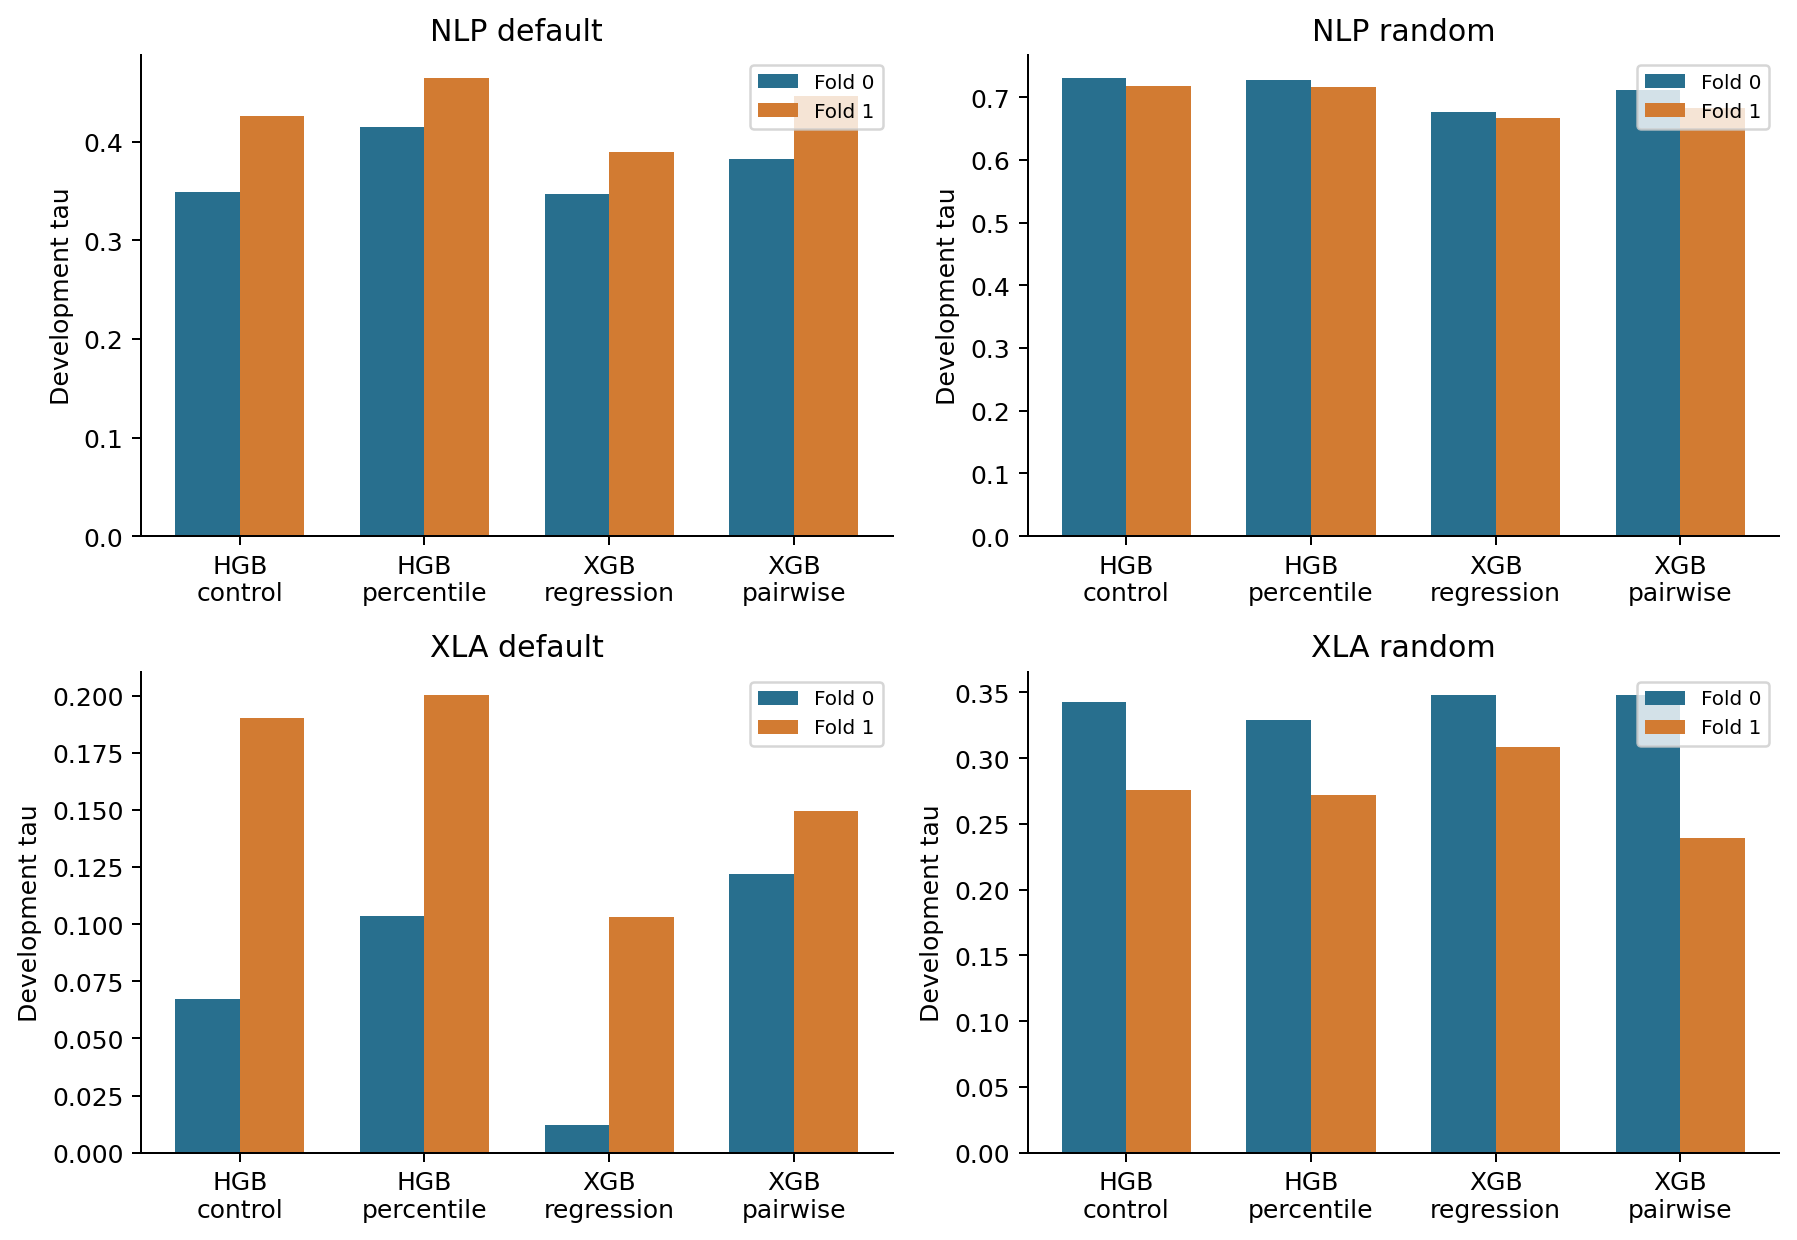

,collection,dev_gain,baseline_score,candidate_score,mean_paired_gain,graphs,bootstrap_low,bootstrap_high
0,layout:nlp:default,0.066477,0.411263,0.453579,0.042316,20,0.022174,0.063437
1,layout:nlp:random,0.005016,0.672493,0.684280,0.011787,20,0.006799,0.018001
2,layout:xla:default,0.029271,0.035175,0.094348,0.059173,7,0.031275,0.092724
3,layout:xla:random,0.000000,0.271156,0.271156,0.000000,7,0.000000,0.000000


In [8]:
show_figure("06_target_and_objective")
display(table("target_blend_audit")[["collection", "dev_gain", "baseline_score",
    "candidate_score", "mean_paired_gain", "graphs", "bootstrap_low", "bootstrap_high"]])


## 6. Final results and interpretation

The table and audit chart compare the frozen system with the basic HGB baseline. The
stronger tabular comparison is also retained in the underlying `final_system_sources`
table. In particular, the XLA random hybrid does not outperform the earlier tabular
ensemble on every audit comparison; selection was made on development data, not by
reselecting whichever model later looked best on the audit set.

All three accepted final updates improve both development folds and their reused audit
scores. Audit gains versus the preceding selected system are **+0.0423** (NLP default),
**+0.0118** (NLP random), and **+0.0592** (XLA default). XLA audit sets contain only seven
graphs; NLP sets contain twenty. Bootstrap intervals are exploratory, not corrected for
multiple comparisons, and the audit has been inspected before.

The user-reported public score increased from **0.558 to 0.567**, an absolute gain of
**0.009**, approximately **1.61% relative**. Three collections changed together, so we
cannot attribute that exact public gain to a single collection. Earlier baseline/tabular/
hybrid scores in the chart are approximate conversation reports, not independently verified
measurements. Add the Kaggle screenshot and exact ranking position before submitting the
report. We do not infer a top-10% ranking from the score.


,collection,baseline,final_selected,audit_graphs
0,layout:nlp:default,0.256342,0.453579,20
1,layout:nlp:random,0.379548,0.684280,20
2,layout:xla:default,0.010947,0.094348,7
3,layout:xla:random,0.128663,0.271156,7
4,tile:xla,0.950500,0.979279,24


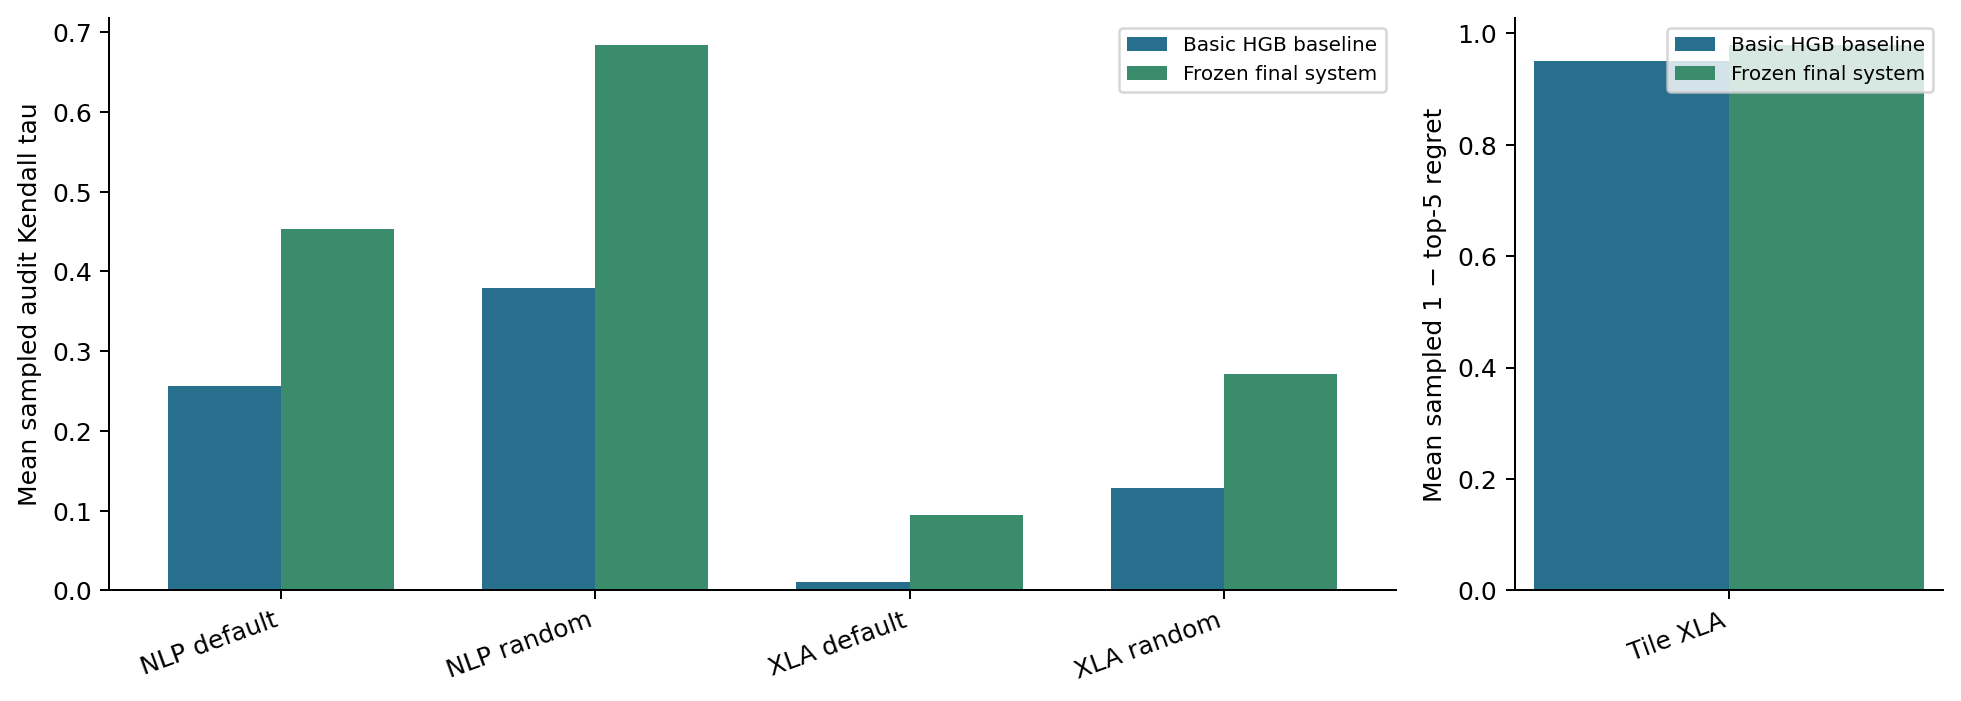

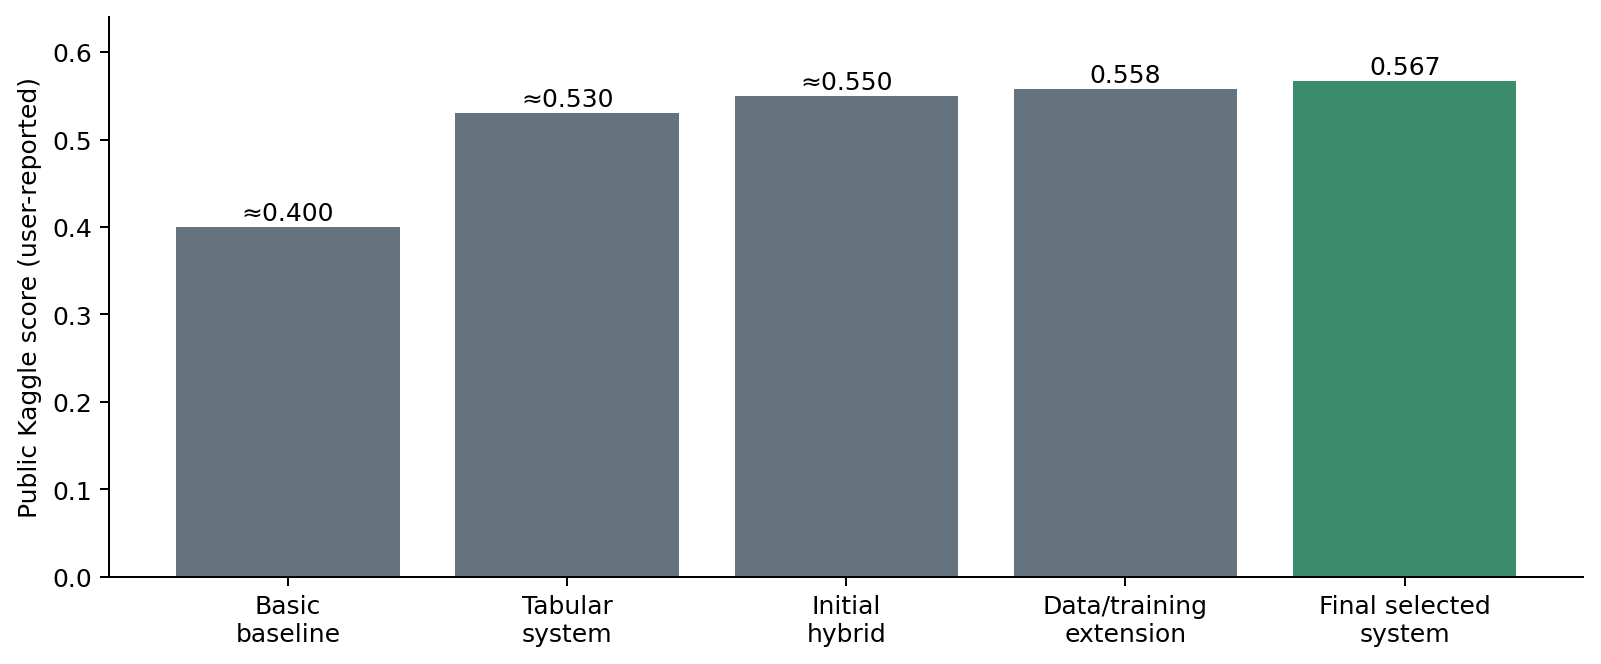

In [9]:
display(table("baseline_and_final_audit"))
show_figure("07_final_audit")
show_figure("08_public_scores")


## 7. Training behaviour and resource constraints

These curves come from the **GNN checkpoints actually used in the final ensemble**,
not the rejected longer-training candidates. Each line is one fold/seed; dots mark saved
selected epochs. The left panel is training loss; the right panel is development ranking
score on the smaller early-stopping subset. They have different units and should not be
plotted as two comparable losses.

A falling training loss with declining development tau can indicate overfitting. A
plateau indicates little additional validation benefit. Early stopping limits training
past the best observed checkpoint, but the curves do **not** prove absence of overfitting.
There is no recorded per-epoch validation-loss series to reconstruct honestly, and these
GNN curves do not diagnose the entire HGB/GNN ensemble.

In the saved curves, XLA random training loss generally decreases while development
scores fluctuate and often peak before the last epoch. XLA default is less stable,
with several low or near-zero development trajectories. These observations support
checkpoint selection and explicit uncertainty, not a claim of uniformly successful
GNN training or no overfitting.

The resource chart shows measured worker peaks and wall times for the target/objective
study. Parallel jobs were admitted only after pilots and memory/CPU checks, with sequential
fallback. Summed worker time is not total elapsed time. Streamed preparation and repeated
feature extraction can remain expensive even when worker RAM use is small.


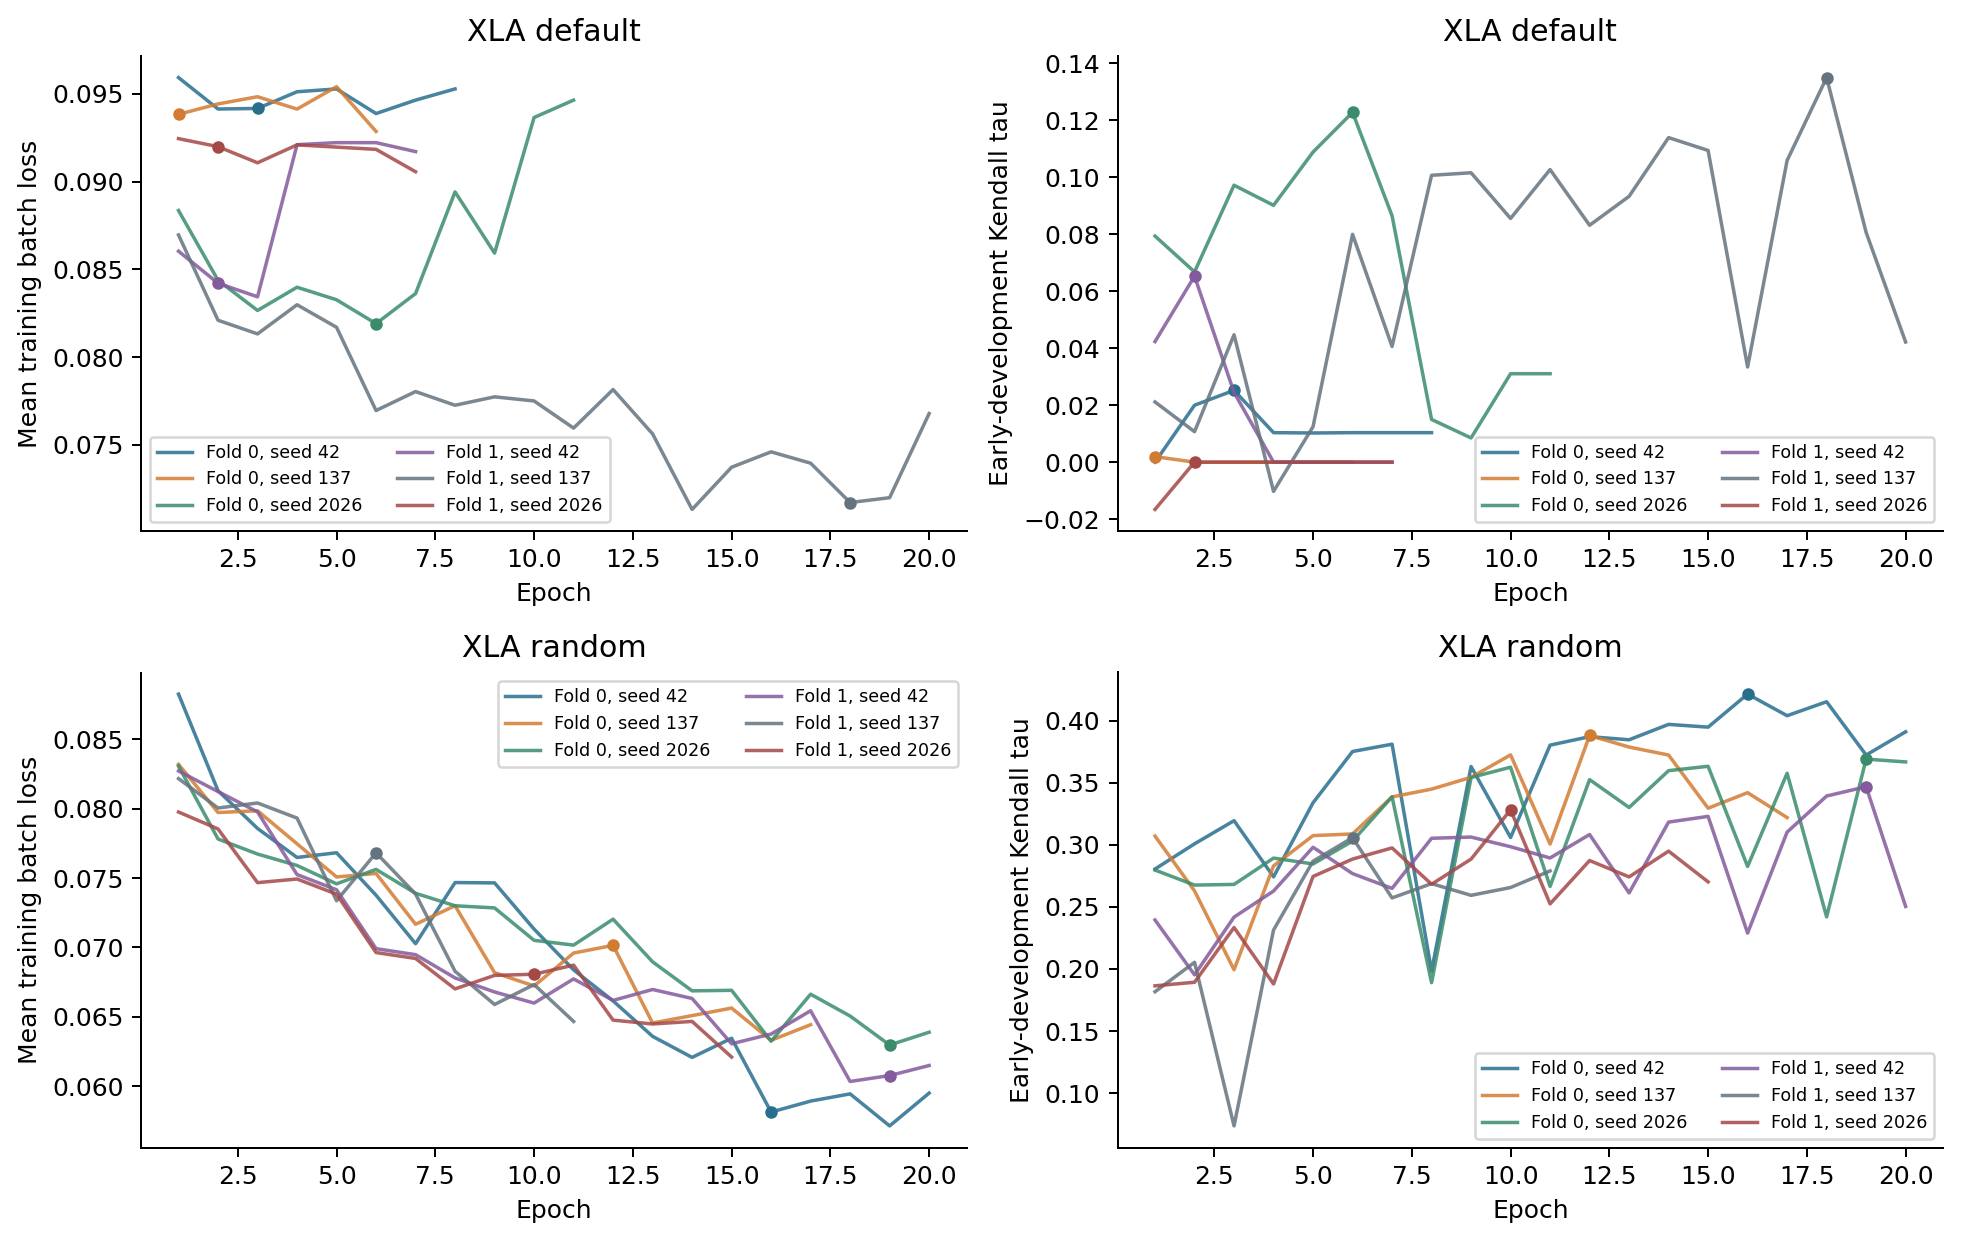

,collection,fold,seed,selected_epoch,epochs_run,first_loss,last_loss,selected_dev_tau,last_dev_tau
0,layout:xla:default,0,42,3,8,0.095927,0.095281,0.025177,0.010344
1,layout:xla:default,0,137,1,6,0.093835,0.092858,0.001932,0.000000
2,layout:xla:default,0,2026,6,11,0.088353,0.094643,0.122693,0.031016
3,layout:xla:default,1,42,2,7,0.086033,0.091710,0.065223,0.000000
4,layout:xla:default,1,137,18,20,0.086958,0.076780,0.134886,0.042145
5,layout:xla:default,1,2026,2,7,0.092448,0.090562,0.000000,0.000000
6,layout:xla:random,0,42,16,20,0.088257,0.059507,0.421603,0.391196
7,layout:xla:random,0,137,12,17,0.083196,0.064433,0.388227,0.322044
8,layout:xla:random,0,2026,19,20,0.083068,0.063893,0.369203,0.366913
9,layout:xla:random,1,42,19,20,0.082718,0.061495,0.346954,0.250428


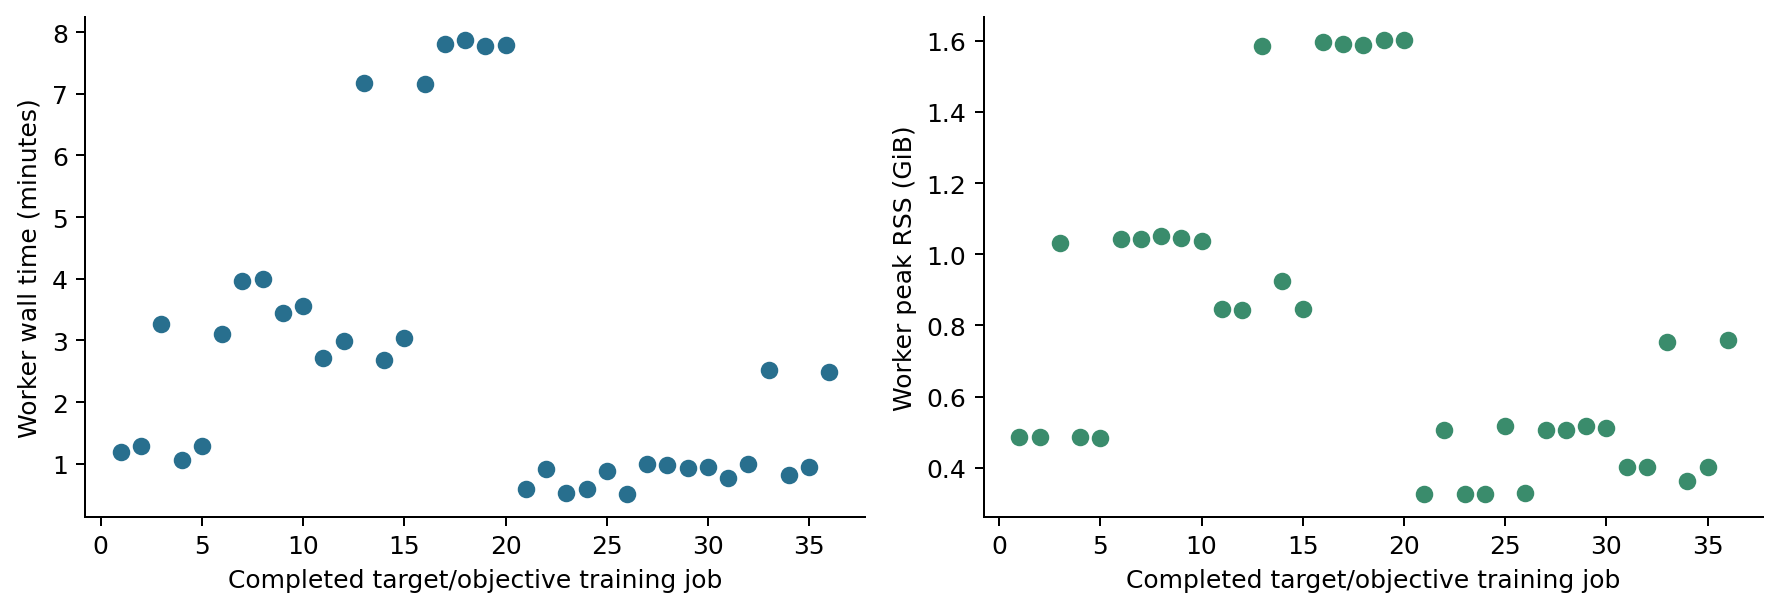

In [10]:
show_figure("09_gnn_learning_curves")
display(table("gnn_learning_diagnostics"))
show_figure("10_training_resources")


## 8. Freeze, provenance and submission export

The compact evidence pack includes measured results, selected recipes, underlying source
code for inspection, and hashes for all **60 selected saved model files**. It does not
contain the model weights. Keep the complete checkpoint ZIP as the model archive.

The following cell optionally verifies that archive by streaming each selected file's
hash. It does not load model objects. Reproducing fresh predictions from raw NPZs remains
a separate saved-model inference task using the archived code and exact dependency
versions; exporting the saved submission below is explicitly **prediction replay**, not
fresh inference or retraining.


In [11]:
if MODEL_ARCHIVE:
    print(final_report.verify_model_archive(MODEL_ARCHIVE, EVIDENCE_DIR))
else:
    print("Full model archive check skipped; compact evidence integrity was verified.")
print("Original trained-model dependency versions:")
display(final_report.read(EVIDENCE_DIR / "run_identity.json")["versions"])
SUBMISSION = final_report.export_submission(EVIDENCE_DIR, OUTPUT_DIR)
print("Verified submission:", SUBMISSION)
print(final_report.validate_submission(EVIDENCE_DIR))


Full model archive check skipped; compact evidence integrity was verified.
Original trained-model dependency versions:


{'numpy': '2.1.3',
 'pandas': '2.2.3',
 'scipy': '1.16.3',
 'scikit-learn': '1.6.1',
 'torch': '2.11.0+cpu',
 'joblib': '1.6.0',
 'psutil': '5.9.5',
 'xgboost': '3.0.5',
 'threadpoolctl': '3.6.0',
 'matplotlib': '3.10.6'}

Verified submission: /Users/eugeneng1150/Documents/sc4000/output/final_notebook_run/sc4000_final_frozen/submission_final.csv
{'rows': 894, 'sha256': 'dc037f378ddb9d0892c283a26a7f31170ac6cc01e937e4d14f2847296ff80312', 'collections': 5}


## 9. Report and presentation handoff

Organize the report around **one solution**, not notebook version numbers:

1. Task, challenges, group contributions and reported leaderboard result.
2. Preprocessing, feature design, bounded GNN and collection-specific rank blends.
3. Baselines and controlled ablations; explain both positive and inconclusive results.
4. Final audit/public results, computational constraints and limitations.
5. Conclusions and references.

The supplied course brief requires the AAAI format, **at most ten pages including
references**, a presentation of at most ten minutes, and the prediction CSV or notebook
with saved models to check the reported result. A new full training sweep is not required
by that brief. Keep source code and the saved-model archive for possible checking.

For the ten-page report, prioritize figures 01, 03, 06, 07 and 09; combine or omit the
remaining figures according to space. Tables/figures need explanatory text. Use the
caption file for metric definitions and evidence limits. Complete the team contribution
statement and exact leaderboard screenshot/rank outside this automated evidence pack.

**Attribution:** HGB, GNN message passing, ranking losses and percentile transforms are
established methods; we do not claim to have invented them. Our project contribution is
the implemented representation/combination and the empirical investigation. Acknowledge
any participant code consulted as a reference in the final report; the course prohibits
directly using participant solutions. The repository's research notes retain the reading
trail. Do not claim unproven standalone mask/context gains or novelty of standard methods.

**Stopping decision:** freeze the 0.567 submission and focus on a convincing, reproducible
presentation of the evidence rather than another speculative sweep toward 0.590.


In [12]:
# Small report deliverable: figures, tables, captions, verification and exact CSV.
# Full model archive is deliberately separate and must be retained separately.
REPORT_ZIP = OUTPUT_DIR / "sc4000_final_report_artifacts.zip"
with zipfile.ZipFile(REPORT_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for folder in [OUTPUT_DIR / "figures", OUTPUT_DIR / "tables"]:
        for path in sorted(folder.glob("*")):
            if path.is_file(): archive.write(path, str(path.relative_to(OUTPUT_DIR)))
    for name in ["FIGURE_CAPTIONS.md", "submission_final.csv", "submission_verification.json"]:
        archive.write(OUTPUT_DIR / name, name)
    archive.write(EVIDENCE_DIR / "freeze_manifest.json", "freeze_manifest.json")
print("Report artifacts:", REPORT_ZIP)
print("Kaggle file:", SUBMISSION)
if DOWNLOAD_OUTPUTS:
    try:
        from google.colab import files
        files.download(str(REPORT_ZIP))
        print("Download requested. Verify completion on your computer.")
    except ImportError:
        print("Outside Colab: copy the files from the paths above.")


Report artifacts: /Users/eugeneng1150/Documents/sc4000/output/final_notebook_run/sc4000_final_frozen/sc4000_final_report_artifacts.zip
Kaggle file: /Users/eugeneng1150/Documents/sc4000/output/final_notebook_run/sc4000_final_frozen/submission_final.csv
